# COMPAS Risk Assessment Analysis

### Dataset Loading and Overview

In [1]:
import pandas as pd
cmps = pd.read_csv("compas-scores.csv")
print(cmps.head(10))

cmps.shape
cmps.nunique()

   id                name      first         last compas_screening_date  \
0   1    miguel hernandez     miguel    hernandez            2013-08-14   
1   3         kevon dixon      kevon        dixon            2013-01-27   
2   4            ed philo         ed        philo            2013-04-14   
3   5         marcu brown      marcu        brown            2013-01-13   
4   6  bouthy pierrelouis     bouthy  pierrelouis            2013-03-26   
5   7        marsha miles     marsha        miles            2013-11-30   
6   8       edward riddle     edward       riddle            2014-02-19   
7   9      steven stewart     steven      stewart            2013-08-30   
8  10    elizabeth thieme  elizabeth       thieme            2014-03-16   
9  13           bo bradac         bo       bradac            2013-11-04   

      sex         dob  age          age_cat              race  ...  \
0    Male  1947-04-18   69  Greater than 45             Other  ...   
1    Male  1982-01-22   34        

id                         7214
name                       7158
first                      2800
last                       3950
compas_screening_date       690
sex                           2
dob                        5452
age                          65
age_cat                       3
race                          6
juv_fel_count                11
decile_score                 10
juv_misd_count               10
juv_other_count              10
priors_count                 37
days_b_screening_arrest     423
c_jail_in                  6907
c_jail_out                 6880
c_case_number              7192
c_offense_date              927
c_arrest_date               580
c_days_from_compas          499
c_charge_degree               2
c_charge_desc               437
is_recid                      2
r_case_number              3471
r_charge_degree              10
r_days_from_arrest          201
r_offense_date             1075
r_charge_desc               340
r_jail_in                   972
r_jail_o

### Distribution of Demographic and Risk Variables

In [2]:
cmps["race"].value_counts()

race
African-American    3696
Caucasian           2454
Hispanic             637
Other                377
Asian                 32
Native American       18
Name: count, dtype: int64

In [3]:
cmps["age_cat"].value_counts()

age_cat
25 - 45            4109
Greater than 45    1576
Less than 25       1529
Name: count, dtype: int64

In [4]:
cmps["c_charge_desc"].value_counts()

c_charge_desc
Battery                           1156
arrest case no charge             1137
Possession of Cocaine              474
Grand Theft in the 3rd Degree      425
Driving While License Revoked      200
                                  ... 
Solicit Purchase Cocaine             1
Compulsory Sch Attnd Violation       1
Battery On Fire Fighter              1
Oper Motorcycle W/O Valid DL         1
Possession of XLR11                  1
Name: count, Length: 437, dtype: int64

In [5]:
cmps["sex"].value_counts()

sex
Male      5819
Female    1395
Name: count, dtype: int64

In [6]:
cmps["decile_score"].value_counts()

decile_score
1     1440
2      941
4      769
3      747
5      681
6      641
7      592
8      512
9      508
10     383
Name: count, dtype: int64

In [7]:
cmps["score_text"].value_counts()

score_text
Low       3897
Medium    1914
High      1403
Name: count, dtype: int64

In [8]:
cmps.describe().T

,count,mean,std,min,25%,50%,75%,max
id,7214.0,5501.255753,3175.706870,1.0,2735.25,5509.5,8246.5,11001.0
age,7214.0,34.817993,11.888922,18.0,25.00,31.0,42.0,96.0
juv_fel_count,7214.0,0.067230,0.473972,0.0,0.00,0.0,0.0,20.0
decile_score,7214.0,4.509565,2.856396,1.0,2.00,4.0,7.0,10.0
juv_misd_count,7214.0,0.090934,0.485239,0.0,0.00,0.0,0.0,13.0
juv_other_count,7214.0,0.109371,0.501586,0.0,0.00,0.0,0.0,17.0
priors_count,7214.0,3.472415,4.882538,0.0,0.00,2.0,5.0,38.0
days_b_screening_arrest,6907.0,3.304763,75.809505,-414.0,-1.00,-1.0,0.0,1057.0
c_days_from_compas,7192.0,57.731368,329.740215,0.0,1.00,1.0,2.0,9485.0
is_recid,7214.0,0.481148,0.499679,0.0,0.00,0.0,1.0,1.0


array([[<Axes: title={'center': 'id'}>, <Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'juv_fel_count'}>,
        <Axes: title={'center': 'decile_score'}>],
       [<Axes: title={'center': 'juv_misd_count'}>,
        <Axes: title={'center': 'juv_other_count'}>,
        <Axes: title={'center': 'priors_count'}>,
        <Axes: title={'center': 'days_b_screening_arrest'}>],
       [<Axes: title={'center': 'c_days_from_compas'}>,
        <Axes: title={'center': 'is_recid'}>,
        <Axes: title={'center': 'r_days_from_arrest'}>,
        <Axes: title={'center': 'violent_recid'}>],
       [<Axes: title={'center': 'is_violent_recid'}>,
        <Axes: title={'center': 'decile_score.1'}>,
        <Axes: title={'center': 'v_decile_score'}>,
        <Axes: title={'center': 'priors_count.1'}>],
       [<Axes: title={'center': 'start'}>,
        <Axes: title={'center': 'end'}>,
        <Axes: title={'center': 'event'}>,
        <Axes: title={'center': 'two_year_recid'}>]], dtype=

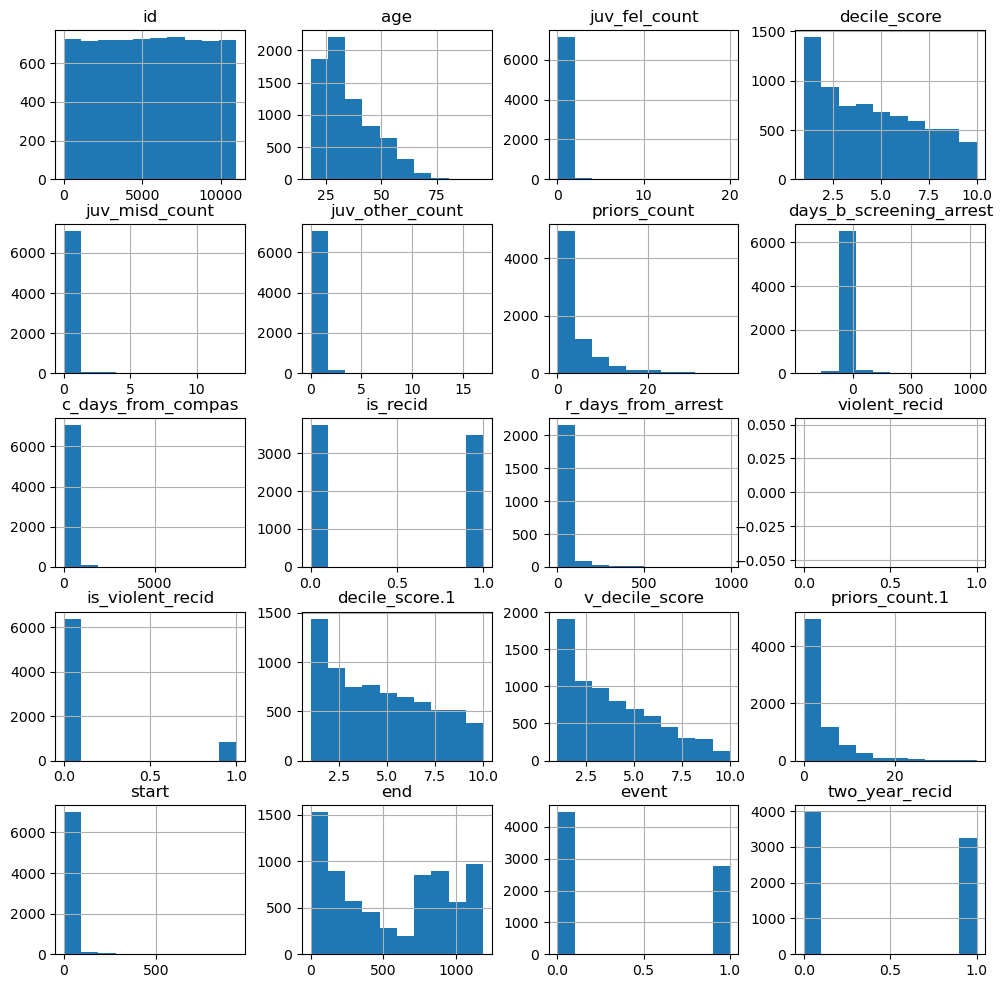

In [9]:
cmps.hist(figsize=(12,12))

### Analysis of Outcomes by Race and Gender

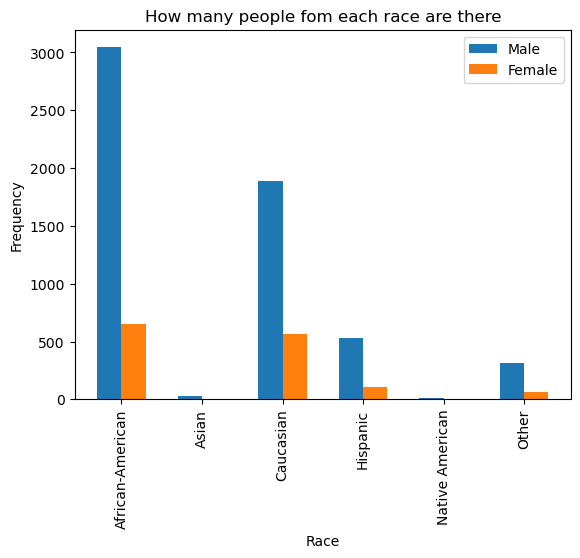

In [10]:
import matplotlib.pyplot as plt
import numpy as np

races = ['African-American','Asian','Caucasian','Hispanic','Native American','Other']
raceGender_counts = cmps.groupby(['race','sex'],observed = True).size().unstack(fill_value = 0).reindex(races)

raceGroups = raceGender_counts.index
m_counts = raceGender_counts['Male']
f_counts = raceGender_counts['Female']

ind = np.arange(len(races))
width =0.3

plt.figure()
plt.bar(ind-width/2, m_counts, width, label='Male')
plt.bar(ind+width/2, f_counts, width, label='Female')

plt.xlabel ('Race')
plt.ylabel ('Frequency')
plt.title ('How many people fom each race are there')
plt.xticks(ind, raceGroups, rotation = 90)
plt.legend()
plt.show()

### Confusion Matrix Analysis

##### Female confusion matrix

Confusion matrix: female
TP_female= 303 FN_female= 195
FP_female= 288 TN_female= 609


<function matplotlib.pyplot.show(close=None, block=None)>

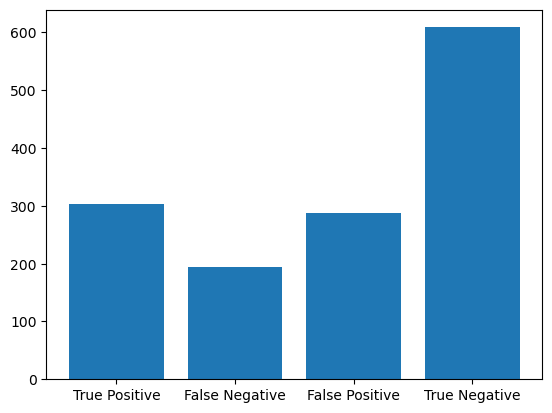

In [11]:
female = cmps[cmps['sex'] == 'Female']
TP_female = len(female[(female['decile_score']>4) & (female['two_year_recid'] == 1 )])
FN_female = len(female[(female['decile_score']<=4) & (female['two_year_recid'] == 1 )])
FP_female = len(female[(female['decile_score']>4) & (female['two_year_recid'] == 0 )])
TN_female = len(female[(female['decile_score']<=4) & (female['two_year_recid'] == 0 )])
 
print('Confusion matrix: female')
print('TP_female=',TP_female,'FN_female=',FN_female)
print('FP_female=',FP_female,'TN_female=',TN_female)

values =[TP_female,FN_female,FP_female,TN_female]
TPs = ['True Positive','False Negative','False Positive','True Negative']
plt.bar(TPs, values)
plt.show

##### Male confusion matrix

Confusion matrix: male
TP_male= 1732 FN_male= 1021
FP_male= 994 TN_male= 2072


<function matplotlib.pyplot.show(close=None, block=None)>

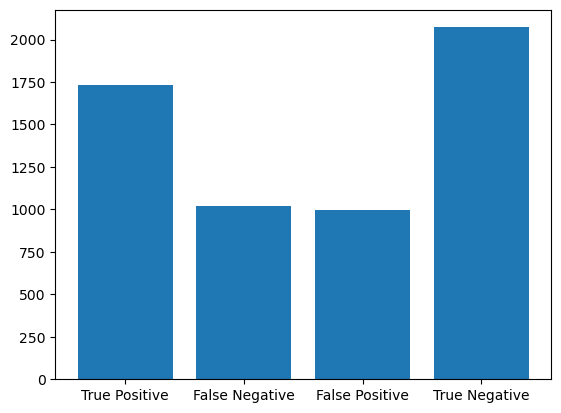

In [12]:
male = cmps[cmps['sex'] == 'Male']
TP_male = len(male[(male['decile_score']>4) & (male['two_year_recid'] == 1 )])
FN_male = len(male[(male['decile_score']<=4) & (male['two_year_recid'] == 1 )])
FP_male = len(male[(male['decile_score']>4) & (male['two_year_recid'] == 0 )])
TN_male = len(male[(male['decile_score']<=4) & (male['two_year_recid'] == 0 )])
 
print('Confusion matrix: male')
print('TP_male=',TP_male,'FN_male=',FN_male)
print('FP_male=',FP_male,'TN_male=',TN_male)

values =[TP_male,FN_male,FP_male,TN_male]
TPs = ['True Positive','False Negative','False Positive','True Negative']
plt.bar(TPs, values)
plt.show

##### African-American confusion matrix

Confusion matrix: African-American
TP_African-American= 1369 FN_African-American= 532
FP_African-American= 805 TN_African-American= 990


<function matplotlib.pyplot.show(close=None, block=None)>

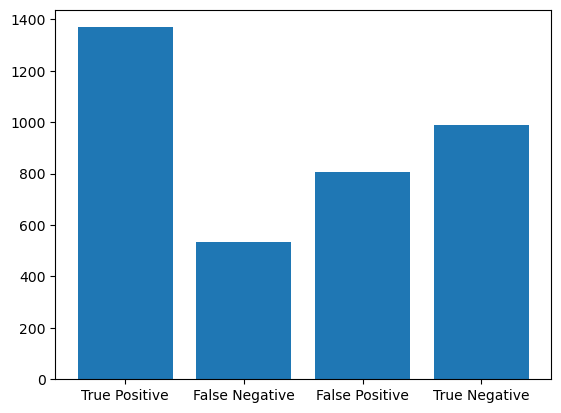

In [13]:
afrAmer = cmps[cmps['race'] == 'African-American']
TP_afrAmer = len(afrAmer[(afrAmer['decile_score']>4) & (afrAmer['two_year_recid'] == 1 )])
FN_afrAmer = len(afrAmer[(afrAmer['decile_score']<=4) & (afrAmer['two_year_recid'] == 1 )])
FP_afrAmer = len(afrAmer[(afrAmer['decile_score']>4) & (afrAmer['two_year_recid'] == 0 )])
TN_afrAmer = len(afrAmer[(afrAmer['decile_score']<=4) & (afrAmer['two_year_recid'] == 0 )])
 
print('Confusion matrix: African-American')
print('TP_African-American=',TP_afrAmer,'FN_African-American=',FN_afrAmer)
print('FP_African-American=',FP_afrAmer,'TN_African-American=',TN_afrAmer)

values =[TP_afrAmer,FN_afrAmer,FP_afrAmer,TN_afrAmer]
TPs = ['True Positive','False Negative','False Positive','True Negative']
plt.bar(TPs, values)
plt.show


##### Caucasian confusion matrix

Confusion matrix: Caucasian
TP_Caucasian= 505 FN_Caucasian= 461
FP_Caucasian= 349 TN_Caucasian= 1139


<function matplotlib.pyplot.show(close=None, block=None)>

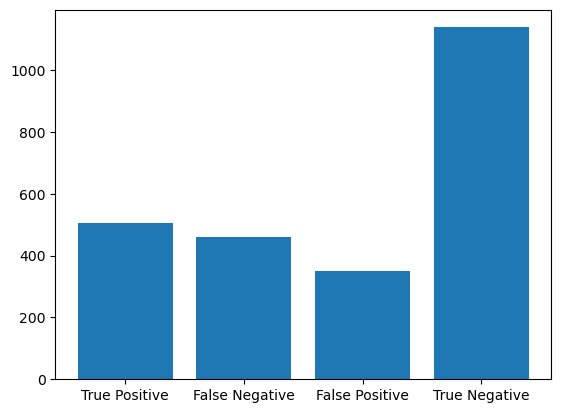

In [14]:
Caucasian = cmps[cmps['race'] == 'Caucasian']
TP_Caucasian = len(Caucasian[(Caucasian['decile_score']>4) & (Caucasian['two_year_recid'] == 1 )])
FN_Caucasian = len(Caucasian[(Caucasian['decile_score']<=4) & (Caucasian['two_year_recid'] == 1 )])
FP_Caucasian = len(Caucasian[(Caucasian['decile_score']>4) & (Caucasian['two_year_recid'] == 0 )])
TN_Caucasian = len(Caucasian[(Caucasian['decile_score']<=4) & (Caucasian['two_year_recid'] == 0 )])
 
print('Confusion matrix: Caucasian')
print('TP_Caucasian=',TP_Caucasian,'FN_Caucasian=',FN_Caucasian)
print('FP_Caucasian=',FP_Caucasian,'TN_Caucasian=',TN_Caucasian)

values =[TP_Caucasian,FN_Caucasian,FP_Caucasian,TN_Caucasian]
TPs = ['True Positive','False Negative','False Positive','True Negative']
plt.bar(TPs, values)
plt.show

##### Hispanic confusion matrix

Confusion matrix: Hispanic
TP_Hispanic= 103 FN_Hispanic= 129
FP_Hispanic= 87 TN_Hispanic= 318


<function matplotlib.pyplot.show(close=None, block=None)>

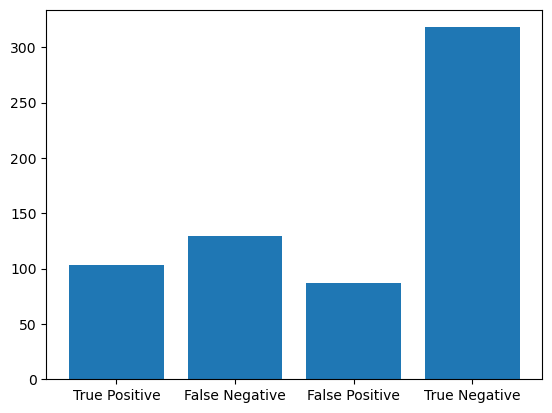

In [15]:
Hispanic = cmps[cmps['race'] == 'Hispanic']
TP_Hispanic = len(Hispanic[(Hispanic['decile_score']>4) & (Hispanic['two_year_recid'] == 1 )])
FN_Hispanic = len(Hispanic[(Hispanic['decile_score']<=4) & (Hispanic['two_year_recid'] == 1 )])
FP_Hispanic= len(Hispanic[(Hispanic['decile_score']>4) & (Hispanic['two_year_recid'] == 0 )])
TN_Hispanic = len(Hispanic[(Hispanic['decile_score']<=4) & (Hispanic['two_year_recid'] == 0 )])
 
print('Confusion matrix: Hispanic')
print('TP_Hispanic=',TP_Hispanic,'FN_Hispanic=',FN_Hispanic)
print('FP_Hispanic=',FP_Hispanic,'TN_Hispanic=',TN_Hispanic)

values =[TP_Hispanic,FN_Hispanic,FP_Hispanic,TN_Hispanic]
TPs = ['True Positive','False Negative','False Positive','True Negative']
plt.bar(TPs, values)
plt.show

##### Native American confusion matrix

Confusion matrix: Native American
TP_Native_American= 9 FN_Native_American= 1
FP_Native_American= 3 TN_Native_American= 5


<function matplotlib.pyplot.show(close=None, block=None)>

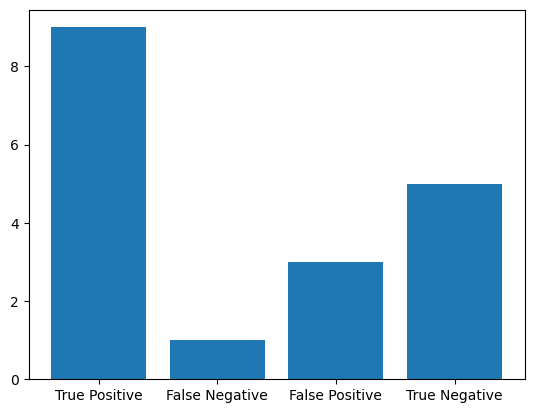

In [16]:
Native_American = cmps[cmps['race'] == 'Native American']
TP_Native_American = len(Native_American[(Native_American['decile_score']>4) & (Native_American['two_year_recid'] == 1 )])
FN_Native_American = len(Native_American[(Native_American['decile_score']<=4) & (Native_American['two_year_recid'] == 1 )])
FP_Native_American= len(Native_American[(Native_American['decile_score']>4) & (Native_American['two_year_recid'] == 0 )])
TN_Native_American = len(Native_American[(Native_American['decile_score']<=4) & (Native_American['two_year_recid'] == 0 )])

print('Confusion matrix: Native American')
print('TP_Native_American=',TP_Native_American,'FN_Native_American=',FN_Native_American)
print('FP_Native_American=',FP_Native_American,'TN_Native_American=',TN_Native_American)

values =[TP_Native_American,FN_Native_American,FP_Native_American,TN_Native_American]
TPs = ['True Positive','False Negative','False Positive','True Negative']
plt.bar(TPs, values)
plt.show


##### Asian confusion matrix

Confusion matrix: Asian
TP_Asian= 6 FN_Asian= 3
FP_Asian= 2 TN_Asian= 21


<function matplotlib.pyplot.show(close=None, block=None)>

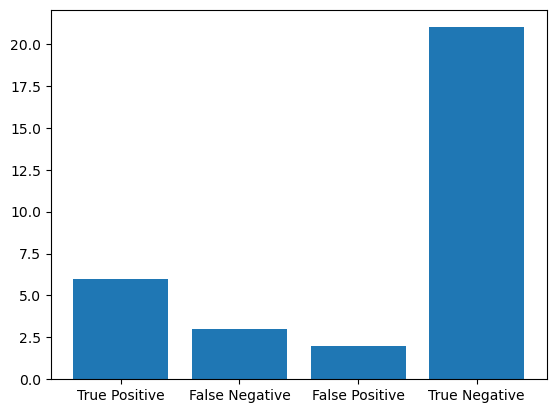

In [17]:
Asian = cmps[cmps['race'] == 'Asian']
TP_Asian = len(Asian[(Asian['decile_score']>4) & (Asian['two_year_recid'] == 1 )])
FN_Asian = len(Asian[(Asian['decile_score']<=4) & (Asian['two_year_recid'] == 1 )])
FP_Asian= len(Asian[(Asian['decile_score']>4) & (Asian['two_year_recid'] == 0 )])
TN_Asian = len(Asian[(Asian['decile_score']<=4) & (Asian['two_year_recid'] == 0 )])

print('Confusion matrix: Asian')
print('TP_Asian=',TP_Asian,'FN_Asian=',FN_Asian)
print('FP_Asian=',FP_Asian,'TN_Asian=',TN_Asian)

values =[TP_Asian,FN_Asian,FP_Asian,TN_Asian]
TPs = ['True Positive','False Negative','False Positive','True Negative']
plt.bar(TPs, values)
plt.show

##### Other confusion matrix

Confusion matrix: Other
TP_Other= 43 FN_Other= 90
FP_Other= 36 TN_Other= 208


<function matplotlib.pyplot.show(close=None, block=None)>

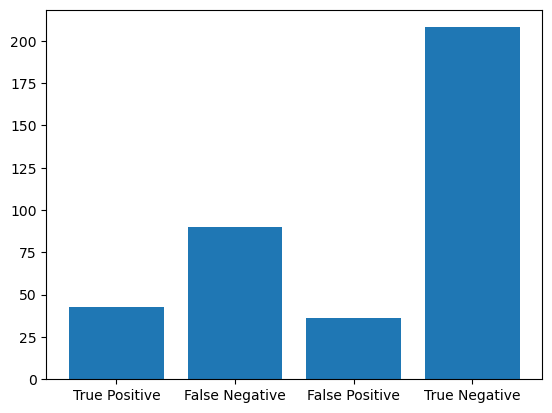

In [18]:
Other = cmps[cmps['race'] == 'Other']
TP_Other = len(Other[(Other['decile_score']>4) & (Other['two_year_recid'] == 1 )])
FN_Other = len(Other[(Other['decile_score']<=4) & (Other['two_year_recid'] == 1 )])
FP_Other= len(Other[(Other['decile_score']>4) & (Other['two_year_recid'] == 0 )])
TN_Other = len(Other[(Other['decile_score']<=4) & (Other['two_year_recid'] == 0 )])

print('Confusion matrix: Other')
print('TP_Other=',TP_Other,'FN_Other=',FN_Other)
print('FP_Other=',FP_Other,'TN_Other=',TN_Other)

values =[TP_Other,FN_Other,FP_Other,TN_Other]
TPs = ['True Positive','False Negative','False Positive','True Negative']
plt.bar(TPs, values)
plt.show


### Comparison of Predictive Performance Across Demographic Groups

In [19]:
Fem = TP_female/(TP_female+FP_female)
print('Female PPV=',Fem)
Mal = TP_male/(TP_male+FP_male)
print('Male PPV=',Mal)
Afr = TP_afrAmer/(TP_afrAmer+FP_afrAmer)
print('African-American PPV=',Afr)
Cau = TP_Caucasian/(TP_Caucasian+FP_Caucasian)
print('Caucasian PPV=',Cau)
His = TP_Hispanic/(TP_Hispanic+FP_Hispanic)
print('Hispanic PPV=',His)
Nat = TP_Native_American/(TP_Native_American+FP_Native_American)
print('Native American PPV=',Nat)
Asi = TP_Asian/(TP_Asian+FP_Asian)
print('Asian PPV=',Asi)
Oth = TP_Other/(TP_Other+FP_Other)
print('Other PPV=',Oth)

Female PPV= 0.5126903553299492
Male PPV= 0.6353631694790902
African-American PPV= 0.6297148114075437
Caucasian PPV= 0.5913348946135831
Hispanic PPV= 0.5421052631578948
Native American PPV= 0.75
Asian PPV= 0.75
Other PPV= 0.5443037974683544


### Visualisation of Performance Metrics

##### The PPVs for the different gender groups

<function matplotlib.pyplot.show(close=None, block=None)>

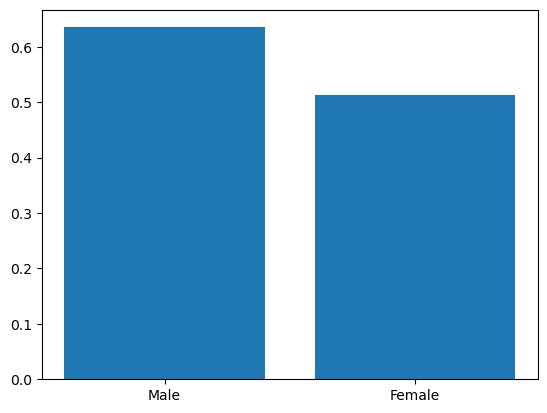

In [20]:
sex_ppvs = [Mal,Fem]
sex = cmps['sex'].value_counts()
plt.bar(sex.index,sex_ppvs)
plt.show

##### The PPVs for the different race groups

<function matplotlib.pyplot.show(close=None, block=None)>

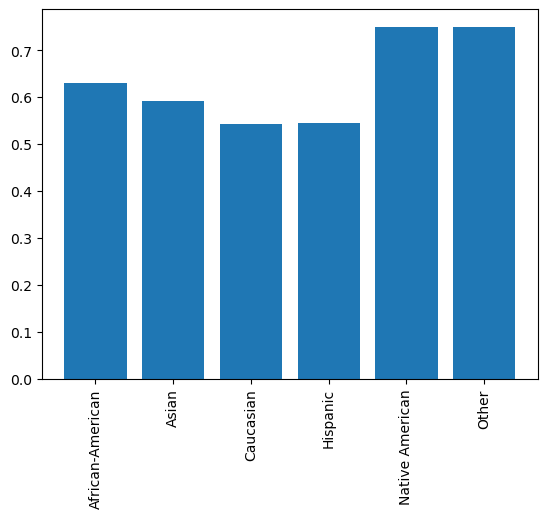

In [21]:
race_ppvs = [Afr, Cau, His, Oth, Asi, Nat]
race = cmps['race'].value_counts()
plt.bar(race.index, race_ppvs)
races = ['African-American','Asian','Caucasian','Hispanic','Native American','Other']

plt.xticks(ind, races, rotation = 90)
plt.show